# Tu primera red neuronal: clasificar dígitos escritos a mano (MNIST)

**Objetivo:** entrenar una red que vea una imagen de 28×28 píxeles y diga qué número es, del 0 al 9.

**Plan:**
1. Cargar y mirar los datos.
2. Modelo 1: una red "densa" (MLP), la más simple posible.
3. Entender el bucle de entrenamiento, que es igual en cualquier red.
4. Evaluar: precisión, matriz de confusión y en qué se equivoca.
5. Modelo 2: una red convolucional (CNN), la base de lo que usarás con imágenes satelitales.

**La idea en una frase:** una red neuronal es una función con muchos parámetros (pesos). Le mostramos
ejemplos, medimos qué tan mal responde (la *pérdida*) y ajustamos los pesos un poquito en la dirección
que reduce esa pérdida. Repetimos miles de veces.

Ejecuta las celdas en orden con `Shift + Enter`.

## 0. Preparación

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)  # para que los resultados se puedan repetir

# Dónde se hacen las cuentas: la GPU de tu Mac (mps) si está disponible, si no la CPU.
device = "mps" if torch.backends.mps.is_available() else "cpu"
print("Usando:", device)

Usando: mps


## 1. Los datos

MNIST trae 70,000 imágenes de dígitos: 60,000 para entrenar y 10,000 para probar al final.

Dos transformaciones a cada imagen:
- `ToTensor()`: convierte la imagen en un **tensor** (un arreglo numérico como los de NumPy) con valores de 0 a 1.
- `Normalize(media, desviación)`: centra los valores alrededor de 0. Las redes aprenden mejor así.
  Los números 0.1307 y 0.3081 son la media y la desviación estándar de los píxeles de MNIST.

In [2]:
transformacion = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,)),
])

entrenamiento_completo = datasets.MNIST("data", train=True, download=True, transform=transformacion)
prueba = datasets.MNIST("data", train=False, download=True, transform=transformacion)

# Apartamos 5,000 imágenes de entrenamiento como "validación": sirven para vigilar el
# entrenamiento sin tocar el conjunto de prueba, que se usa una sola vez al final.
entrenamiento, validacion = random_split(entrenamiento_completo, [55_000, 5_000])

print(len(entrenamiento), "entrenamiento |", len(validacion), "validación |", len(prueba), "prueba")

55000 entrenamiento | 5000 validación | 10000 prueba


Cada elemento es una pareja `(imagen, etiqueta)`. La imagen tiene forma `[1, 28, 28]`:
1 canal (escala de grises), 28 filas y 28 columnas. Una foto a color tendría 3 canales; una imagen
Sentinel-2 tiene 13.

Forma: torch.Size([1, 28, 28]) | Etiqueta: 6


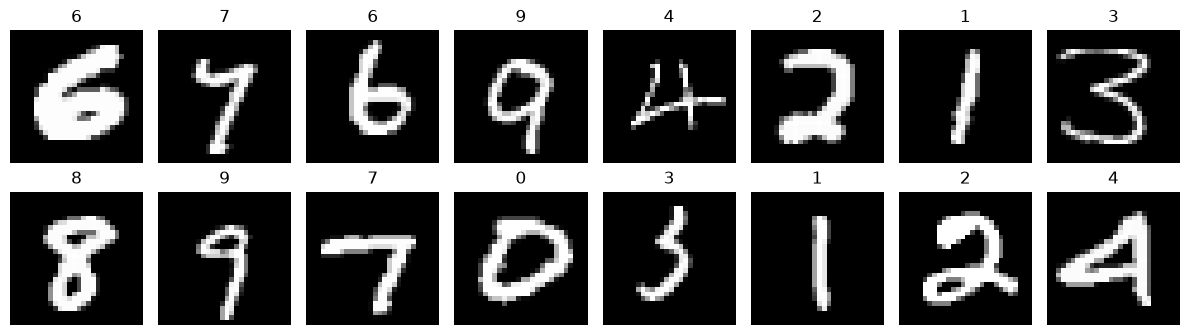

In [3]:
imagen, etiqueta = entrenamiento[0]
print("Forma:", imagen.shape, "| Etiqueta:", etiqueta)

fig, ejes = plt.subplots(2, 8, figsize=(12, 3.5))
for i, eje in enumerate(ejes.flat):
    img, et = entrenamiento[i]
    eje.imshow(img.squeeze(), cmap="gray")
    eje.set_title(et)
    eje.axis("off")
plt.tight_layout()

**DataLoader:** en lugar de pasar las imágenes una por una, se pasan en lotes (*batches*) de 64.
Es más rápido y el aprendizaje es más estable. `shuffle=True` revuelve el orden en cada época para
que la red no memorice la secuencia.

In [4]:
cargador_entrenamiento = DataLoader(entrenamiento, batch_size=64, shuffle=True)
cargador_validacion = DataLoader(validacion, batch_size=1000)
cargador_prueba = DataLoader(prueba, batch_size=1000)

imagenes, etiquetas = next(iter(cargador_entrenamiento))
print("Un lote de imágenes:", imagenes.shape)  # [64, 1, 28, 28]
print("Sus etiquetas:", etiquetas.shape)       # [64]

Un lote de imágenes: torch.Size([64, 1, 28, 28])
Sus etiquetas: torch.Size([64])


## 2. Modelo 1: red densa (MLP)

La versión más simple:
1. `Flatten`: aplana la imagen de 28×28 en una fila de 784 números.
2. `Linear(784, 128)`: 128 neuronas; cada una calcula una suma ponderada de los 784 píxeles.
3. `ReLU`: deja pasar los positivos y convierte los negativos en 0. Sin esta no-linealidad,
   apilar capas sería lo mismo que tener una sola.
4. `Linear(128, 10)`: 10 salidas, una por dígito.

Las 10 salidas se llaman **logits**: puntajes sin escala. El dígito con el puntaje más alto es la
predicción. Si les aplicas `softmax` se convierten en probabilidades que suman 1.

In [5]:
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(28 * 28, 128),
    nn.ReLU(),
    nn.Linear(128, 10),
)

def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())

print(mlp)
print(f"Parámetros: {contar_parametros(mlp):,}")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Parámetros: 101,770


Antes de entrenar, los pesos son aleatorios. Mira lo que "predice" con un lote: debería acertar
alrededor del 10 %, lo mismo que adivinar al azar.

In [6]:
with torch.no_grad():  # no necesitamos gradientes para solo mirar
    logits = mlp(imagenes)
print("Logits de la primera imagen:", logits[0].numpy().round(2))
print("Predicciones:", logits.argmax(dim=1)[:16].tolist())
print("Respuestas:  ", etiquetas[:16].tolist())

Logits de la primera imagen: [ 0.21 -0.22 -0.38  0.07 -0.07  0.1  -0.13 -0.09  0.05 -0.  ]
Predicciones: [0, 0, 8, 5, 0, 0, 3, 0, 5, 1, 3, 9, 7, 5, 8, 5]
Respuestas:   [0, 1, 1, 0, 5, 6, 1, 2, 4, 9, 4, 1, 9, 8, 4, 4]


## 3. Cómo aprende: pérdida, optimizador y bucle de entrenamiento

- **Pérdida (`CrossEntropyLoss`):** un número que mide qué tan mal está la predicción. Es baja cuando
  la red le da un puntaje alto al dígito correcto. Es la pérdida estándar para clasificación.
- **Optimizador (`Adam`):** decide cuánto mover cada peso. `lr` (*learning rate*) es el tamaño del paso:
  muy grande y la red no converge; muy chico y tarda una eternidad. 0.001 es un buen punto de partida.

Para cada lote, el bucle hace siempre los mismos 5 pasos:

1. **Forward:** pasar las imágenes por la red y obtener predicciones.
2. **Pérdida:** comparar predicciones con las etiquetas reales.
3. `zero_grad()`: borrar los gradientes del lote anterior (PyTorch los acumula si no).
4. `backward()`: *backpropagation*. Calcula cuánto contribuyó cada peso al error (el gradiente).
5. `step()`: mover cada peso un poco en contra de su gradiente.

Una **época** es pasar una vez por todo el conjunto de entrenamiento.

In [7]:
def entrenar_una_epoca(modelo, cargador, perdida_fn, optimizador):
    modelo.train()  # activa el modo entrenamiento (importa para Dropout, que verás en la CNN)
    total_perdida, aciertos, n = 0.0, 0, 0
    for imagenes, etiquetas in cargador:
        imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)

        logits = modelo(imagenes)                # 1. forward
        perdida = perdida_fn(logits, etiquetas)  # 2. pérdida
        optimizador.zero_grad()                  # 3. borrar gradientes viejos
        perdida.backward()                       # 4. backpropagation
        optimizador.step()                       # 5. actualizar pesos

        total_perdida += perdida.item() * len(etiquetas)
        aciertos += (logits.argmax(dim=1) == etiquetas).sum().item()
        n += len(etiquetas)
    return total_perdida / n, aciertos / n


@torch.no_grad()
def evaluar(modelo, cargador, perdida_fn):
    modelo.eval()  # modo evaluación: sin Dropout
    total_perdida, aciertos, n = 0.0, 0, 0
    for imagenes, etiquetas in cargador:
        imagenes, etiquetas = imagenes.to(device), etiquetas.to(device)
        logits = modelo(imagenes)
        total_perdida += perdida_fn(logits, etiquetas).item() * len(etiquetas)
        aciertos += (logits.argmax(dim=1) == etiquetas).sum().item()
        n += len(etiquetas)
    return total_perdida / n, aciertos / n


def entrenar(modelo, epocas=5, lr=1e-3):
    modelo.to(device)
    perdida_fn = nn.CrossEntropyLoss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=lr)
    historial = {"perdida_ent": [], "perdida_val": [], "precision_ent": [], "precision_val": []}
    for epoca in range(1, epocas + 1):
        p_ent, a_ent = entrenar_una_epoca(modelo, cargador_entrenamiento, perdida_fn, optimizador)
        p_val, a_val = evaluar(modelo, cargador_validacion, perdida_fn)
        for clave, valor in zip(historial, [p_ent, p_val, a_ent, a_val]):
            historial[clave].append(valor)
        print(f"Época {epoca}: pérdida {p_ent:.3f} / {p_val:.3f} | precisión {a_ent:.1%} / {a_val:.1%}  (entrenamiento / validación)")
    return historial

¡A entrenar! En una Mac M1 tarda menos de un minuto.

In [8]:
historial_mlp = entrenar(mlp, epocas=5)

Época 1: pérdida 0.268 / 0.164 | precisión 92.2% / 95.1%  (entrenamiento / validación)


Época 2: pérdida 0.117 / 0.118 | precisión 96.5% / 96.4%  (entrenamiento / validación)


Época 3: pérdida 0.082 / 0.095 | precisión 97.5% / 97.2%  (entrenamiento / validación)


Época 4: pérdida 0.064 / 0.107 | precisión 98.0% / 97.1%  (entrenamiento / validación)


Época 5: pérdida 0.049 / 0.084 | precisión 98.4% / 97.4%  (entrenamiento / validación)


**Cómo leer las curvas:**
- Si la pérdida de entrenamiento baja y la de validación también, la red está aprendiendo.
- Si la de entrenamiento sigue bajando pero la de validación empieza a subir, hay **sobreajuste**
  (*overfitting*): la red memoriza los ejemplos en lugar de aprender a generalizar.

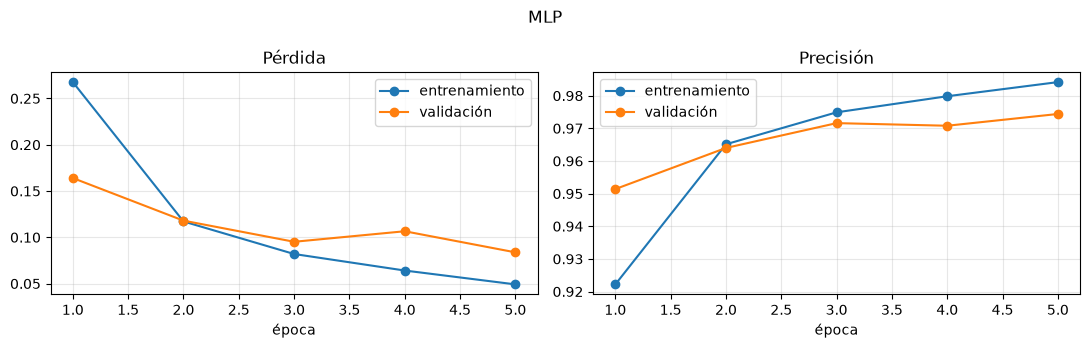

In [9]:
def graficar_historial(historial, titulo):
    fig, (e1, e2) = plt.subplots(1, 2, figsize=(11, 3.5))
    epocas = range(1, len(historial["perdida_ent"]) + 1)
    e1.plot(epocas, historial["perdida_ent"], "o-", label="entrenamiento")
    e1.plot(epocas, historial["perdida_val"], "o-", label="validación")
    e1.set(title="Pérdida", xlabel="época")
    e2.plot(epocas, historial["precision_ent"], "o-", label="entrenamiento")
    e2.plot(epocas, historial["precision_val"], "o-", label="validación")
    e2.set(title="Precisión", xlabel="época")
    for e in (e1, e2):
        e.legend()
        e.grid(alpha=0.3)
    fig.suptitle(titulo)
    plt.tight_layout()

graficar_historial(historial_mlp, "MLP")

## 4. Evaluación en el conjunto de prueba

Ahora sí usamos las 10,000 imágenes de prueba, que la red nunca vio.

In [10]:
@torch.no_grad()
def predecir(modelo, cargador):
    modelo.eval()
    todas_pred, todas_et = [], []
    for imagenes, etiquetas in cargador:
        todas_pred.append(modelo(imagenes.to(device)).argmax(dim=1).cpu())
        todas_et.append(etiquetas)
    return torch.cat(todas_pred).numpy(), torch.cat(todas_et).numpy()

pred_mlp, reales = predecir(mlp, cargador_prueba)
print(f"Precisión en prueba (MLP): {(pred_mlp == reales).mean():.2%}")

Precisión en prueba (MLP): 97.56%


**Matriz de confusión:** filas = dígito real, columnas = predicción. La diagonal son los aciertos;
fuera de ella ves qué dígitos confunde (típicamente 4↔9, 3↔5, 7↔2).

Text(0.5, 1.0, 'MLP: matriz de confusión')

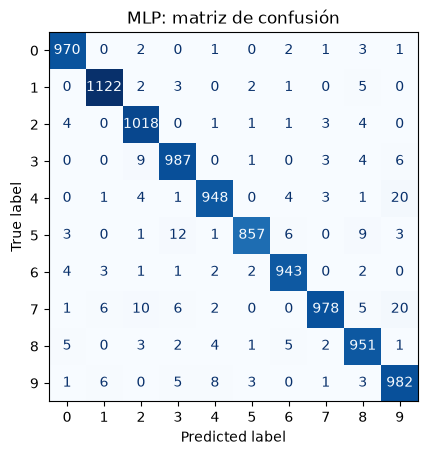

In [11]:
ConfusionMatrixDisplay(confusion_matrix(reales, pred_mlp)).plot(cmap="Blues", colorbar=False)
plt.title("MLP: matriz de confusión")

Veamos algunos errores. Varios son difíciles hasta para una persona.

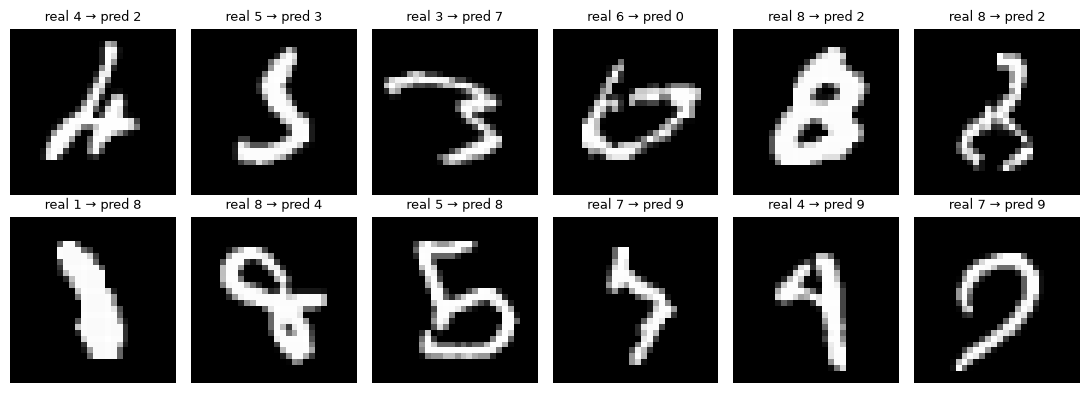

In [12]:
def mostrar_errores(predicciones, n=12):
    errores = np.where(predicciones != reales)[0][:n]
    fig, ejes = plt.subplots(2, 6, figsize=(11, 4))
    for eje, i in zip(ejes.flat, errores):
        eje.imshow(prueba[i][0].squeeze(), cmap="gray")
        eje.set_title(f"real {reales[i]} → pred {predicciones[i]}", fontsize=9)
        eje.axis("off")
    plt.tight_layout()

mostrar_errores(pred_mlp)

## 5. Modelo 2: red convolucional (CNN)

El MLP tiene un defecto: al aplanar la imagen pierde la noción de "qué píxel está junto a cuál".
Una **CNN** recorre la imagen con filtros pequeños (3×3) que detectan patrones locales: bordes,
curvas, esquinas. Las capas siguientes combinan esos patrones en formas más complejas.

- `Conv2d(1, 32, 3, padding=1)`: 32 filtros de 3×3. La salida son 32 "mapas" de 28×28.
- `MaxPool2d(2)`: reduce cada mapa a la mitad quedándose con el valor máximo de cada cuadro de 2×2.
- Tras dos bloques: 64 mapas de 7×7 → se aplanan → capa densa → 10 salidas.
- `Dropout(0.25)`: durante el entrenamiento apaga al azar el 25 % de las neuronas. Así la red no
  depende de unas pocas y generaliza mejor.

Es la misma idea que usarás con Sentinel-2 (ResNet es una CNN mucho más profunda).

In [13]:
cnn = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3, padding=1),   # [32, 28, 28]
    nn.ReLU(),
    nn.MaxPool2d(2),                              # [32, 14, 14]
    nn.Conv2d(32, 64, kernel_size=3, padding=1),  # [64, 14, 14]
    nn.ReLU(),
    nn.MaxPool2d(2),                              # [64, 7, 7]
    nn.Flatten(),                                 # [3136]
    nn.Linear(64 * 7 * 7, 128),
    nn.ReLU(),
    nn.Dropout(0.25),
    nn.Linear(128, 10),
)
print(f"Parámetros: {contar_parametros(cnn):,}")

Parámetros: 421,642


Época 1: pérdida 0.163 / 0.055 | precisión 94.9% / 98.2%  (entrenamiento / validación)


Época 2: pérdida 0.055 / 0.043 | precisión 98.3% / 98.6%  (entrenamiento / validación)


Época 3: pérdida 0.039 / 0.033 | precisión 98.8% / 99.0%  (entrenamiento / validación)


Época 4: pérdida 0.032 / 0.040 | precisión 99.0% / 98.9%  (entrenamiento / validación)


Época 5: pérdida 0.025 / 0.042 | precisión 99.2% / 98.8%  (entrenamiento / validación)


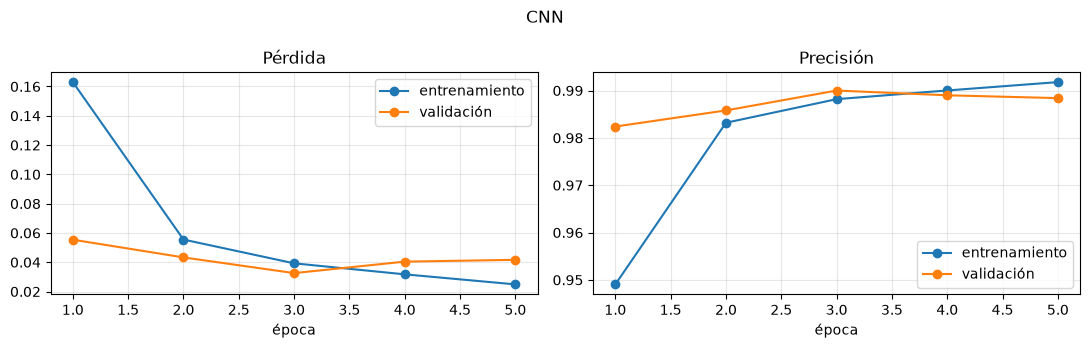

In [14]:
historial_cnn = entrenar(cnn, epocas=5)
graficar_historial(historial_cnn, "CNN")

In [15]:
pred_cnn, _ = predecir(cnn, cargador_prueba)
print(f"Precisión en prueba: MLP {(pred_mlp == reales).mean():.2%} | CNN {(pred_cnn == reales).mean():.2%}")
print(f"Errores: MLP {(pred_mlp != reales).sum()} | CNN {(pred_cnn != reales).sum()} de {len(reales):,}")

Precisión en prueba: MLP 97.56% | CNN 98.95%
Errores: MLP 244 | CNN 105 de 10,000


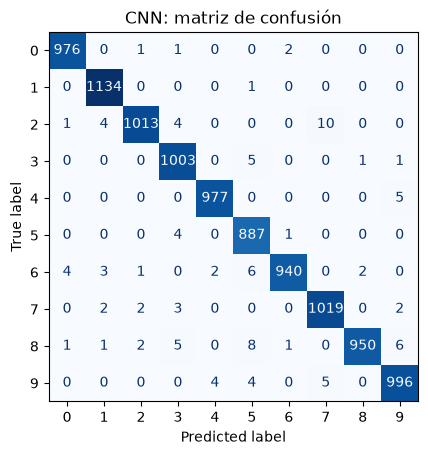

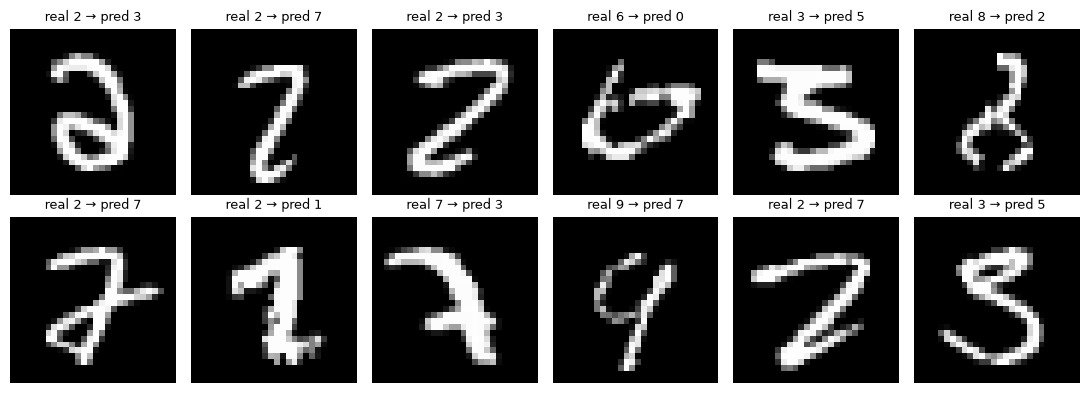

In [16]:
ConfusionMatrixDisplay(confusion_matrix(reales, pred_cnn)).plot(cmap="Blues", colorbar=False)
plt.title("CNN: matriz de confusión")
mostrar_errores(pred_cnn)

### ¿Qué "ven" los filtros?

Los 32 filtros de la primera capa, después de entrenar. Cada uno aprendió a reaccionar a un patrón
distinto (bordes horizontales, verticales, diagonales...). Nadie se los programó.

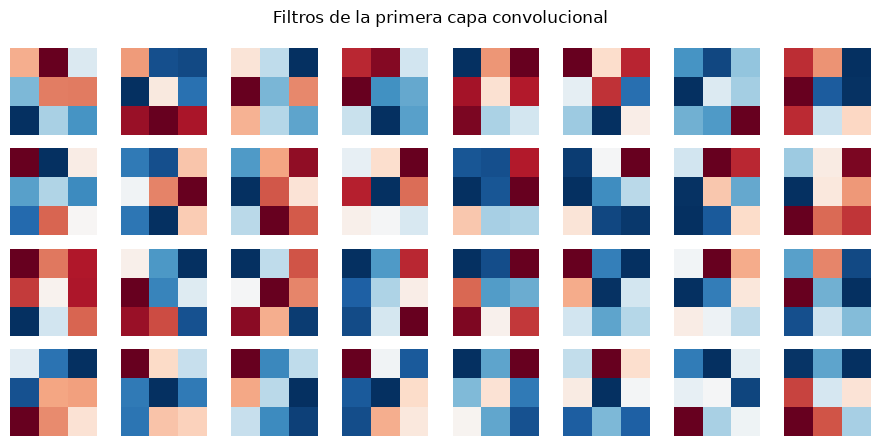

In [17]:
filtros = cnn[0].weight.detach().cpu().squeeze()  # [32, 3, 3]
fig, ejes = plt.subplots(4, 8, figsize=(9, 4.5))
for eje, f in zip(ejes.flat, filtros):
    eje.imshow(f, cmap="RdBu")
    eje.axis("off")
plt.suptitle("Filtros de la primera capa convolucional")
plt.tight_layout()

## 6. Una predicción con probabilidades

`softmax` convierte los logits en probabilidades. Así ves qué tan segura está la red.

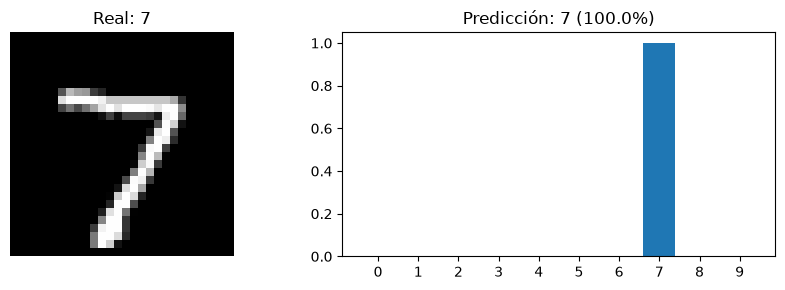

In [18]:
i = 0  # cambia este índice para probar otras imágenes de prueba
imagen, etiqueta = prueba[i]
cnn.eval()
with torch.no_grad():
    probabilidades = torch.softmax(cnn(imagen.unsqueeze(0).to(device)), dim=1).squeeze().cpu()

fig, (e1, e2) = plt.subplots(1, 2, figsize=(9, 3))
e1.imshow(imagen.squeeze(), cmap="gray")
e1.set_title(f"Real: {etiqueta}")
e1.axis("off")
e2.bar(range(10), probabilidades)
e2.set(xticks=range(10), title=f"Predicción: {probabilidades.argmax().item()} ({probabilidades.max():.1%})")
plt.tight_layout()

## 7. Guardar el modelo

In [19]:
torch.save(cnn.state_dict(), "data/cnn_mnist.pt")
# Para cargarlo después: crea la misma arquitectura y usa cnn.load_state_dict(torch.load("data/cnn_mnist.pt"))

## 8. Ejercicios para practicar

Haz uno a la vez y anota qué pasa con la precisión de validación:

1. **Learning rate:** entrena el MLP con `lr=0.1` y con `lr=0.00001`. ¿Qué pasa con la pérdida?
2. **Tamaño:** cambia las 128 neuronas del MLP por 16 y por 512. ¿Más grande siempre es mejor?
3. **Profundidad:** agrega otra capa `Linear` + `ReLU` al MLP.
4. **Sobreajuste a propósito:** entrena el MLP 30 épocas con solo 1,000 imágenes
   (`random_split(entrenamiento_completo, [1_000, 59_000])`) y mira cómo se separan las curvas.
5. **Sin ReLU:** quita las `ReLU` del MLP. ¿Cuánto cae la precisión y por qué?
6. **Fashion-MNIST:** cambia `datasets.MNIST` por `datasets.FashionMNIST` (ropa en lugar de dígitos,
   misma forma). Es bastante más difícil: ¿cuánto saca cada modelo?

**Conceptos que ya viste:** tensor, lote, época, capa densa, ReLU, logits, softmax, pérdida de entropía
cruzada, gradiente, backpropagation, optimizador, learning rate, validación, sobreajuste, convolución,
pooling y dropout.